In [ ]:
import os
from enum import StrEnum
from typing import Optional, Literal

import polars as pl
from matplotlib import pyplot as plt, rcParams, patches as mpatches, colors as mcolors
from matplotlib.axes import Axes
import seaborn as sns

import synapseclient
from synapseclient.entity import File as sceFile 

rcParams["font.family"] = "Arial"
rcParams["font.size"] = 7

In [223]:
# Jupyter server should be running from src/python
LIMMA_RESULTS = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_cache",
    "limma",
    "limma_results.parquet"
)

FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures"
)

LIMMA_RESULTS_SYNID = "syn78408378"

### Synapse login token/session

In [217]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.14.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.14.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



In [ ]:
REUPLOAD_LIMMA_RESULTS = False

if REUPLOAD_LIMMA_RESULTS:
    # upload limma results to synapse
    SYN.store(sceFile(path=LIMMA_RESULTS, id=LIMMA_RESULTS_SYNID))

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_64161/2068509991.py:5: DeprecationWarning: Call to deprecated method store. (To be removed in 5.0.0. Use `from synapseclient.operations import store` instead.) -- Deprecated since version 4.11.0.
  SYN.store(sceFile(path=LIMMA_RESULTS, id=LIMMA_RESULTS_SYNID))



In [17]:
# ensure the figures directory exists
os.makedirs(FIGURE_DIR, exist_ok=True)

In [222]:
results = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)

results

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_64161/3971302718.py:1: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  results = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)


[syn78408378]: Downloaded to /Users/dylan.ross/.synapseCache/553/178866553/limma_results.parquet


logFC,AveExpr,t,P.Value,adj.P.Val,B,Feature,OmicsType,Contrast
f64,f64,f64,f64,f64,f64,str,str,str
-0.081511,-0.11285,-0.538509,0.590664,0.709686,-6.672805,"""ACAA2-K234k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
0.287721,-0.009539,2.585739,0.010234,0.033313,-3.541081,"""ACAD9-K202k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
-0.232181,-0.117167,-1.862395,0.063618,0.143931,-5.107354,"""ACADM-K304k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
0.002934,-0.290974,0.01853,0.985229,0.994583,-6.816371,"""ACADVL-K278k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
-0.11039,-0.142724,-0.959001,0.338404,0.484085,-6.361222,"""ACADVL-K298k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
…,…,…,…,…,…,…,…,…
-0.030516,0.37894,-0.169126,0.86588,0.98462,-5.801028,"""ENSG00000266232""","""Transcriptomics""","""White_NPM1+/FLT3-ITD+_vs_White…"
-0.119107,0.47479,-0.772661,0.440698,0.900046,-5.540732,"""ENSG00000201863""","""Transcriptomics""","""White_NPM1+/FLT3-ITD+_vs_White…"
-0.049692,0.454784,-0.360979,0.718522,0.963672,-5.754391,"""ENSG00000206926""","""Transcriptomics""","""White_NPM1+/FLT3-ITD+_vs_White…"


In [123]:
with pl.Config(set_tbl_rows=100):
    display(
        results
        .filter(
            (pl.col("logFC").abs() > 1) 
            & (pl.col("adj.P.Val") <= 0.05)
            & (pl.col("Contrast") != "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-")
        )
        .with_columns(pl.when(pl.col("logFC") > 0).then(pl.lit("up")).otherwise(pl.lit("down")).alias("Direction"))
        .group_by("OmicsType", "Contrast", "Direction")
        .len()
        .sort("Contrast", "OmicsType", "Direction")
    )

OmicsType,Contrast,Direction,len
str,str,str,u32
"""Proteomics""","""Black_NPM1+/FLT3-ITD+_vs_Black…","""up""",1
"""Transcriptomics""","""Black_NPM1+/FLT3-ITD+_vs_Black…","""down""",3
"""Acetylomics""","""Black_NPM1+/FLT3-ITD+_vs_Black…","""down""",1
"""Proteomics""","""Black_NPM1+/FLT3-ITD-_vs_Black…","""down""",3
"""Proteomics""","""Black_NPM1+/FLT3-ITD-_vs_Black…","""up""",1
"""Transcriptomics""","""Black_NPM1+/FLT3-ITD-_vs_Black…","""down""",15
"""Transcriptomics""","""Black_NPM1+/FLT3-ITD-_vs_Black…","""up""",125
"""Transcriptomics""","""Black_NPM1-/FLT3-ITD+_vs_Black…","""down""",21
"""Transcriptomics""","""Black_NPM1-/FLT3-ITD+_vs_Black…","""up""",12


In [212]:
class COLORS(StrEnum):
    LABEL_TEXT = "#FFF"
    EDGES = "#000"
    CMAP_MIN = "#44C"
    CMAP_MID = "#CCC"
    CMAP_MAX = "#C44"
    POP_BLACK = "#000"
    POP_WHITE = "#FFF"


# Custom colormap and normalizer centered around 0 in range [-N, +N]
N = 100
CMAP = mcolors.LinearSegmentedColormap.from_list(
    "custom_map", 
    [COLORS.CMAP_MIN, COLORS.CMAP_MID, COLORS.CMAP_MAX]
)
NORM = mcolors.Normalize(vmin=-N, vmax=N, clip=True)


TRI_INNER_PAD = 0.025
LW = 0.75
LABEL_SIZE = 7.5
TEXT_INSET = 0.3
MUT_RADIUS = 0.125
MUT_LABEL_SIZE = 5.5


def _get_mapped_color(count: int) -> str:
    return mcolors.to_hex(CMAP(NORM(count)))


def _plot_counts_triangles(
        ax: Axes,
        n_up: Optional[int],
        n_down: Optional[int],
):
    # setup
    ax.set_axis_off()
    ax.set_aspect("equal")
    ax.set_xlim((0 - TRI_INNER_PAD, 1 + TRI_INNER_PAD))
    ax.set_ylim((0 - TRI_INNER_PAD, 1 + TRI_INNER_PAD))

    if n_up is not None:
        # top triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (0, 1), (1, 1)],
            ec=COLORS.EDGES,
            fc=_get_mapped_color(n_up),
            lw=LW,
            joinstyle="round",
        ))
        # top label
        ax.text(
            TEXT_INSET, 1. - TEXT_INSET,
            f"{n_up:,}",
            fontsize=LABEL_SIZE,
            color=COLORS.LABEL_TEXT,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )
    else:
        # top triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (0, 1), (1, 1)],
            ec=COLORS.CMAP_MID,
            fc="none",
            lw=LW,
            joinstyle="round",
        ))
        # top label
        ax.text(
            TEXT_INSET, 1. - TEXT_INSET,
            "0",
            fontsize=LABEL_SIZE,
            color=COLORS.CMAP_MID,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )

    if n_down is not None:
        # bottom triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (1, 1), (1, 0)],
            ec=COLORS.EDGES,
            fc=_get_mapped_color(-n_down),
            lw=LW,
            joinstyle="round",
        ))
        # bottom label
        ax.text(
            1 - TEXT_INSET, TEXT_INSET,
            f"{n_down:,}",
            fontsize=LABEL_SIZE,
            color=COLORS.LABEL_TEXT,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )
    else:
        # bottom triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (1, 1), (1, 0)],
            ec=COLORS.CMAP_MID,
            fc="none",
            lw=LW,
            joinstyle="round",
        ))
        # bottom label
        ax.text(
            1 - TEXT_INSET, TEXT_INSET,
            "0",
            fontsize=LABEL_SIZE,
            color=COLORS.CMAP_MID,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )


def _plot_comparison_metadata(
        ax: Axes,
        pop: Optional[Literal["Black", "White"]],
        top_npm1: bool,
        top_flt3: bool,
        bottom_npm1: bool,
        bottom_flt3: bool,

):
    # setup
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_aspect("equal")
    ax.set_xlim((0, 1))
    ax.set_ylim((0, 1))

    # box indicating population
    box_inset = 0.1
    box_height = 0.1
    fc = (
        {"Black": COLORS.POP_BLACK, "White": COLORS.POP_WHITE}[pop] 
        if pop is not None 
        else "none"
    )
    ax.add_patch(mpatches.Rectangle(
        (box_inset, 1 - box_inset - box_height),
        1 - 2 * box_inset, 
        box_height,
        ec=COLORS.EDGES,
        fc=fc,
        lw=LW,
        hatch="//////" if fc == "none" else None
    ))

    # mutations
    metadata_divider_x_inset = 0.1
    xmin = metadata_divider_x_inset
    xmax = 1 - metadata_divider_x_inset
    ymin = metadata_divider_x_inset
    divider_height = 0.5
    ymax = ymin + divider_height
    ax.plot(
        [xmin, xmax],
        [ymin, ymax],
        ls="--",
        lw=LW,
        c=COLORS.POP_BLACK,
    )

    dx = 0.1 
    dy = 0.2
    for point, flag, mut in zip(
        [
            (xmin + dx / 2, ymin + 1.5 * dy), 
            (xmin + 3 * dx, ymin + 2 * dy), 
            (xmax - dx / 2, ymax - 1.5 * dy), 
            (xmax - 3 * dx, ymax - 2 * dy)
        ],
        [top_npm1, top_flt3, bottom_flt3, bottom_npm1],
        "NFFN"
    ):
        ax.add_patch(mpatches.Circle(
            point,
            MUT_RADIUS,
            ec=COLORS.EDGES,
            fc=COLORS.EDGES if flag else COLORS.LABEL_TEXT,
            lw=LW
        ))
        ax.text(
            point[0], point[1] - 0.01,
            mut,
            fontsize=MUT_LABEL_SIZE,
            color=COLORS.LABEL_TEXT if flag else COLORS.EDGES,
            fontweight="bold",
            ha="center", va="center"
        )
    
    ax.set_xticks([])
    ax.set_yticks([])

In [213]:
def plot_sig_up_down_feature_counts(
        results: pl.DataFrame, 
        lfc: float, 
        p_value: float, 
        p_adj: bool,
        figname: str
): 
    # key: (contrast, omics type, direction)
    # value: feature count
    counts = {
        tuple(k): v
        for *k, v
        in (
            results
            .filter(
                (pl.col("logFC").abs() > lfc) 
                & (pl.col("adj.P.Val" if p_adj else "P.Value") <= p_value)
            )
            .with_columns(
                pl.when(pl.col("logFC") > 0)
                .then(pl.lit("up"))
                .otherwise(pl.lit("down"))
                .alias("Direction")
            )
            .group_by("OmicsType", "Contrast", "Direction")
            .len()
            .sort("Contrast", "OmicsType", "Direction")
            .select("Contrast", "OmicsType", "Direction", "len")
            .iter_rows()
        )
    }

    SUBPLOT_PAD = 0.1
    SCALE = 0.55

    fig, axs = plt.subplots(
        figsize=(9 * SCALE, 7 * SCALE),
        ncols=9, nrows=7,
    )


    # first column: comparison of white vs. black (WT only for both)
    comparison = "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
    _plot_comparison_metadata(axs[0][0], None, False, False, False, False)
    for y, omics_data_type in enumerate(
            [
                "Transcriptomics",
                "Proteomics",
                "Phosphoproteomics",
                "Acetylomics",
                "Metabolomics",
                "Lipidomics"
            ], 
            start=1
        ):
            _plot_counts_triangles(
                axs[y][0],
                counts.get((comparison, omics_data_type, "up")),
                counts.get((comparison, omics_data_type, "down")),
                
            )

    x = 1
    for mutations in [
        # NPM1 (top), FLT3-ITD (top), NPM1 (bottom), FLT3-ITD (bottom)
        (True, False, False, False),
        (False, True, False, False),
        (True, True, True, False),
        (True, True, False, True),
    ]:
        for pop in ["Black", "White"]:
            # metadata description
            _plot_comparison_metadata(axs[0][x], pop, *mutations)
            comparison = (
                f"{pop}_"
                f"NPM1{'+' if mutations[0] else '-'}/"
                f"FLT3-ITD{'+' if mutations[1] else '-'}"
                f"_vs_{pop}_"
                f"NPM1{'+' if mutations[2] else '-'}/"
                f"FLT3-ITD{'+' if mutations[3] else '-'}"
            )
            # triangles
            for y, omics_data_type in enumerate(
                [
                    "Transcriptomics",
                    "Proteomics",
                    "Phosphoproteomics",
                    "Acetylomics",
                    "Metabolomics",
                    "Lipidomics"
                ], 
                start=1
            ):
                _plot_counts_triangles(
                    axs[y][x],
                    counts.get((comparison, omics_data_type, "up")),
                    counts.get((comparison, omics_data_type, "down")),
                    
                )
            # next column
            x += 1

    fig.subplots_adjust(wspace=SUBPLOT_PAD, hspace=SUBPLOT_PAD)
    plt.savefig(
        figname,
        dpi=400,
        bbox_inches="tight",
        transparent=True
    )
    plt.show()
    plt.close()

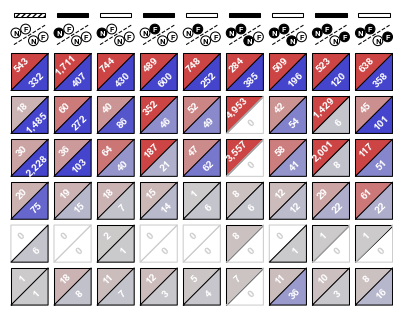

In [214]:
plot_sig_up_down_feature_counts(
    results, 
    lfc=0.5, 
    p_value=0.05,
    p_adj=False,
    figname=os.path.join(FIGURE_DIR, "limma_results_sig_up_down.png")
)

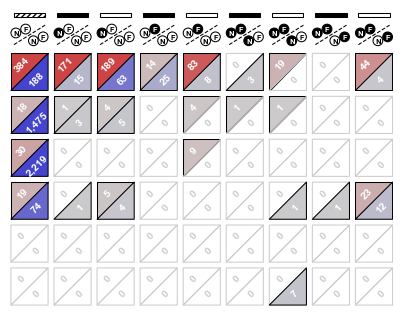

In [215]:
plot_sig_up_down_feature_counts(
    results, 
    lfc=0.5, 
    p_value=0.05,
    p_adj=True,
    figname=os.path.join(FIGURE_DIR, "limma_results_sig_up_down_padj.png")
)